# Week 09 NLP 上机实验 — 中文金融文本分词与情感量化

> 在把文本交给 LLM 之前，先亲手做一遍传统 NLP 的完整流程——**分词 → 词频 → 词典法情感打分 → LLM 情感分析 → 每日情绪曲线 → 情绪与股价的相关性**，理解「文本如何变成数据」，并体会词典法和 LLM 法的边界。约 80–110 分钟。

## 实验环境

1. 已完成 week01 的 Python 环境配置（`py -3.13` + 项目 `.venv`）
2. 依赖（在已激活的 `.venv` 的终端中安装，不要在 notebook 里装）：
   ```
   pip install jieba pandas matplotlib openai python-dotenv
   ```
3. **本 notebook 必须从 `week09/` 目录启动**（`jupyter lab` 或 VS Code 打开），相对路径才能找到数据


| 文件 | 内容 |
|---|---|
| `cleaned_300251_comments.csv` | 光线传媒（300251）股吧评论约 12.4 万条，2011-07 ~ 2019-04，含 `date` 与 `comment` 列 |
| `300251_daily.csv` | 光线传媒日线行情（tushare，教师已导出）：1751 个交易日，含 `trade_date`、`close`、`pct_chg` |
| `stopwordsHIT.txt` | 哈工大停用词表（约 830 词） |
| `userdict.txt` | jieba 自定义词典（金融术语） |
| `zhang_unformal_pos.txt` / `zhang_unformal_neg.txt` | 正 / 负面情感词表（911 / 964 词） |

---

## Part 0：读数据 + 清洗（10 分钟）

真实评论数据很脏：正文里混着 `\r\n` 和成串空格，还有纯表情/数字的空壳评论。

In [ ]:
text ="  利好\r\n   茅台  明天 加仓\t"
# → ['利好茅台', '明天', '加仓']     \r\n、多个空格、\t 全被吃掉

text.split() 

In [ ]:
" ".join(text.split() ) # 切完再拼，效果：所有空白统一压成一个普通空格。

In [2]:
import pandas as pd

df = pd.read_csv("cleaned_300251_comments.csv", parse_dates=["date"])

def clean(text):
    """把 \r\n 和连续空白压成单个空格"""
    return " ".join(text.split()) if isinstance(text, str) else ""

df["text"] = df["comment"].apply(clean)
df = df[df["text"] != ""].reset_index(drop=True)   # 丢掉空评论

print(f"有效评论 {len(df)} 条")
print("时间范围:", df["date"].min(), "->", df["date"].max())


有效评论 124125 条
时间范围: 2011-07-14 21:30:36 -> 2019-04-10 14:59:03


In [ ]:
df[["date", "text"]].head(10)

**观察**：随便看 10 条正文，哪些一看就没有分析价值（纯数字、太短）？你觉得需要多长的最短长度过滤？

,date,text
17975,2013-02-08 13:45:50,000504ST传媒：五大利好！股价将大涨2倍！！！！！！！！！ 000504ST传媒：五大...
21917,2013-04-28 06:53:13,"今年2 季度是光线电影季,《致青春》《中国合伙人》《不二神探》 今年2 季度将是光线电影季，..."
82615,2015-12-21 10:03:09,三只发行同，光线最弱，大家换票哈 三只发行同，光线最弱，大家换票哈
47944,2014-09-23 11:03:27,横盘几天继续跌？要跌就快点，太墨迹了光线 横盘几天继续跌？要跌就快点，太墨迹了光线
113637,2018-08-06 11:53:14,少年强则国强，少年弱则国弱 少年强则国强，少年弱则国弱
3915,2011-08-17 09:56:49,警告：机构出货完毕，散户被套。 警告：机构出货完毕，散户被套。
99141,2017-03-07 15:10:51,2个月了，还是王八股，你到是跌到9元啊，砸 王八
27839,2013-06-24 17:49:14,"明天大力买进, 123"
30200,2013-07-17 15:11:28,"直接涨停,爽啊,那些说跌停的人sb了,哈哈~ gogogo~~~~"
84139,2015-12-30 10:19:22,爆跌才对得起自己拍的那几部烂片，跌吧 爆跌才对得起自己拍的那几部烂片，跌吧


count    124125.0
mean         46.5
std          58.8
min           1.0
25%          21.0
50%          32.0
75%          51.0
max         849.0
Name: text, dtype: float64
不足 5 字: 423 条（0.3%）


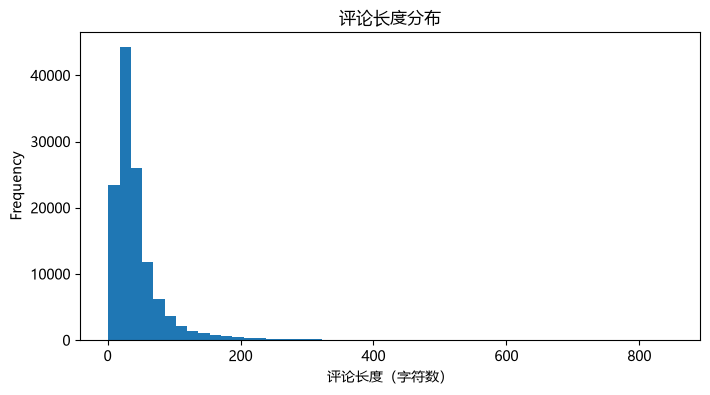

In [3]:
# 试试：多抽几条看看 / 统计一下评论长度的分布
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "PingFang SC", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

# 1) 随机抽 10 条看看（改 random_state 换一批）
display(df[["date", "text"]].sample(10, random_state=42))

# 2) 评论长度分布
lengths = df["text"].str.len()
print(lengths.describe().round(1))
print(f"不足 5 字: {(lengths < 5).sum()} 条（{(lengths < 5).mean():.1%}）")

lengths.plot(kind="hist", bins=50, figsize=(8, 4), title="评论长度分布")
plt.xlabel("评论长度（字符数）")
plt.show()


In [ ]:
# 查看长度小于5的评论
short_comments = df[lengths < 5]
print(f"长度不足 5 字的评论共 {len(short_comments)} 条")
short_comments[["date", "text"]].head(20)


> 💡 **小技巧（个性化你的实验）**：本 notebook 里所有 `random_state=42` 都可以改成**你的学号**（例如 `random_state=20250001`）。这样每个人抽到的评论、算出的一致率都不一样——课堂讨论时对比「你抽到的那条」会很有意思，也便于确认各自独立完成。改完后受影响的格子要重跑一遍。


## Part 1：分词——中文 NLP 的第一道坎（15 分钟）

英文有空格分隔单词，中文没有。「利好茅台明天加仓」是一整串字符，机器不知道哪几个字是一个词。**分词就是把连续文本切成词**。

### 原理速览：机器怎么知道在哪里切？

同一个句子可以有多种切法——「欢迎新老师生前来就餐」既可以是「欢迎 / 新老 / 师生 / 前来 / 就餐」，也可以切成「欢迎 / 新老师 / 生前 / 来 / 就餐」。所谓「最好的切法」需要规则或优化目标来定义，常见方法分两类：

**① 基于规则：最大匹配方法（Maximum Match Method）**

需要一个预定义词典，按「贪心地切出最长的词」来分。步骤：

1. 从句首取 m 个字符作为候选（m = 词典里最长词的长度）；
2. 查词典：**匹配成功** → 切出一个词；**匹配失败** → 去掉最后一个字，再匹配；
3. 重复直到句子切完。从左往右扫是**正向最大匹配**，从右往左是**逆向最大匹配**，两者都跑再择优的是**双向最大匹配**。

> **例**：词典 {南京、南京市、市长、江、大桥、长江、长江大桥}，max_len = 4，对「南京市长江大桥」做正向最大匹配——先取「南京市长」不在词典，去掉「长」→「南京市」命中，切出「南京市」；剩下「长江大桥」→「长江大桥」命中。结果：**南京市 / 长江大桥**。但同一句话也能切成「南京市长 / 江大桥」——规则法只顾「往前贪最长」，无法回头比较整体，这就是歧义问题。

**② 基于统计：统计切词法（语言模型）**

思路换了一个角度：不是「查词」，而是**比较各种切法哪种更可能出现**。语言模型给长度为 n 的词序列分配一个概率 p(w₁, w₂, …, wₙ)，我们选择概率最大的切分结果。

- 最简单的假设是各词独立（uni-gram），联合概率 = 各词概率的乘积；词的概率从语料库的词频统计得到。也可以用 n-gram 考虑词与词的搭配条件概率。
- 概率也可以不靠人工统计，而由序列模型（循环神经网络，乃至今天的大语言模型）来估计。

**jieba = 两种思路的结合**：先利用**前缀词典**找出句中所有可能的切分位置，构造一个**有向无环图（DAG）**；再用**动态规划**算出概率最大的路径，作为最终切分。

了解了原理，我们来看 jieba 在真实股评上的表现：

In [ ]:
import jieba

text = "光线传媒涨停了，稳稳拿住，别追高被套，巨亏辣鸡庄托"

# ① 不加载自定义词典
print(list(jieba.cut(text)))



Building prefix dict from the default dictionary ...
Loading model from cache C:\Users\haichao\AppData\Local\Temp\jieba.cache
Loading model cost 0.791 seconds.
Prefix dict has been built successfully.


['光线', '传媒', '涨停', '了', '，', '稳稳', '拿', '住', '，', '别', '追高', '被套', '，', '巨亏', '辣鸡', '庄托']


In [4]:
# ② 加载金融自定义词典后再分
jieba.load_userdict("userdict.txt")
print(list(jieba.cut(text)))

['光线传媒', '涨停', '了', '，', '稳稳', '拿住', '，', '别', '追高', '被套', '，', '巨亏', '辣鸡', '庄托']


In [5]:
# 再从真实数据抽 3 条检查分词质量
for c in df["text"].sample(30, random_state=42):
    print(c, "->", jieba.lcut(c))

000504ST传媒：五大利好！股价将大涨2倍！！！！！！！！！ 000504ST传媒：五大利好！股价将大涨2倍！！！！！！！！！第一大利好：即将摘ST虽然有些摘ST后，股价大跌，但那些个股在摘ST之前是大涨的，而且股价位置处于高位！目前000504ST传媒股价处于调整阶段，股价位置也在相对低位，如果公布摘ST，其股价必将一字涨停！公司已于1月21日向深交所申请摘ST，本人已经问过有关部分，回答是：很快！耐心等几天。第二大利好：收购北京富宇世纪文化传媒有限公司全部股权，这也意味着ST传媒涉足影视投资业第三大利好：即将定向增发1.2亿股（传闻史玉柱认购1亿股，将成为000504ST传媒的第一大股东），募集资金6亿多元，投向影视公司，转型为影视公司。目前影视公司的股价都很高，最高的是300291华录百纳，目前股价63元多，而000504ST传媒，目前股价才6.66元，一对比就知道：000504ST传媒，转型影视公司后，目前股价严重低估，最少要补涨2倍以上！第四大利好：000504ST传媒旗下的优质资产《中国计算机报》，传闻联想集团拟出大价钱收购！该题材如果被炒作，目前股价会快速翻倍！第五大利好：某大型私募基金超一流研究员，据说该研究员最擅长研究发现ST股中的大机会！据说该研究员认为，在目前还没有怎么涨且处于相对底部的ST股中，000504ST传媒最具备翻倍潜力！特别提醒：000504ST传媒，已经被很多私募基金盯上了，据说北京一大机构早已介入，有该股的注意筹码不要被震丢掉，错失突然连续一字涨停的翻倍行情！ -> ['000504', 'ST', '传媒', '：', '五大', '利好', '！', '股价', '将', '大涨', '2', '倍', '！', '！', '！', '！', '！', '！', '！', '！', '！', ' ', '000504', 'ST', '传媒', '：', '五大', '利好', '！', '股价', '将', '大涨', '2', '倍', '！', '！', '！', '！', '！', '！', '！', '！', '！', '第一', '大', '利好', '：', '即将', '摘', 'ST', '虽然', '有些', '摘', 'ST', '后', '，', '股价', '大跌', '，', '但', '那些

In [ ]:
# 【记录】找出至少 1 条分词分错的评论，写在下面（这一步很重要，思考题要用）
# 分错的评论：
# 错在哪：


### 动手①：自己写一个「正向最大匹配」分词器（约 8 分钟）

jieba 一下就切对了，但它内部做了什么？回到上面的「原理速览」，自己把**正向最大匹配**实现一遍——十几行代码，你会切身体会规则法为什么「简单又笨」。

**任务三步**：

1. 跑通下面的 `max_match_cut`，验证「南京市长江大桥」切成 `['南京市', '长江大桥']`；对照原理讲解在心里走一遍循环，看懂每一步
2. 换你自己的句子试一试：先往 `vocab` 里加几个需要的词（金融词更好），再切
3. **挑战**：构造一个让正向最大匹配**切错**的句子（提示：「研究生命的起源」会被切成什么？），再补全 `max_match_cut_reverse`（从右往左扫的逆向最大匹配），看同一句话两种切法结果是否不同——这就是思考题 1 的第一手素材


In [7]:
def max_match_cut(text, vocab, max_len=4):
    """正向最大匹配：从左往右扫，每一步贪心切出词典里能匹配的最长词"""
    result, i = [], 0
    while i < len(text):
        # 从最长候选开始逐字缩短；全都不在词典里就切单字（L == 1）
        for L in range(min(max_len, len(text) - i), 0, -1):
            if text[i:i+L] in vocab or L == 1:
                result.append(text[i:i+L])
                i += L
                break
    return result

vocab = {"南京", "南京市", "市长", "江", "大桥", "长江", "长江大桥"}

print(max_match_cut("南京市长江大桥", vocab))    # 期望 ['南京市', '长江大桥']

# 任务 2：往 vocab 里加你的词，切你自己的句子
vocab.update({"白酒", "龙头股"})
print(max_match_cut("买入白酒板块龙头股", vocab))



['南京市', '长江大桥']
['买', '入', '白酒', '板', '块', '龙头股']


## Part 2：停用词 + 词频统计（15 分钟）

分出来的词里大量是「的、了、是、吗」——出现最多但对分析没用。这里用**哈工大停用词表**（`stopwordsHIT.txt`），而不是手写几个词：

In [8]:
from collections import Counter
import pandas as pd

# utf-8-sig 会自动去掉文件开头的 BOM 字符
with open("stopwordsHIT.txt", encoding="utf-8-sig") as f:
    stopwords = {w.strip() for w in f if w.strip()}
print(f"停用词 {len(stopwords)} 个")

def tokenize(text):
    """分词 + 去停用词 + 去单字和空白"""
    return [w for w in jieba.lcut(text)
            if w not in stopwords and len(w.strip()) > 1]

# 12 万条全量分词约 1-2 分钟，正好喝口水
words = []
for c in df["text"]:
    words.extend(tokenize(c))

freq = Counter(words)
print(freq.most_common(20))

停用词 834 个
[('光线', 30723), ('光线传媒', 22612), ('今天', 15906), ('票房', 12047), ('涨停', 9873), ('明天', 9514), ('主力', 8832), ('公司', 8103), ('华谊', 7547), ('电影', 7483), ('大家', 7188), ('机构', 6626), ('传媒', 6582), ('没有', 6411), ('垃圾', 6167), ('现在', 6019), ('10', 5835), ('大盘', 5788), ('股票', 5733), ('股价', 5722)]


画成图：

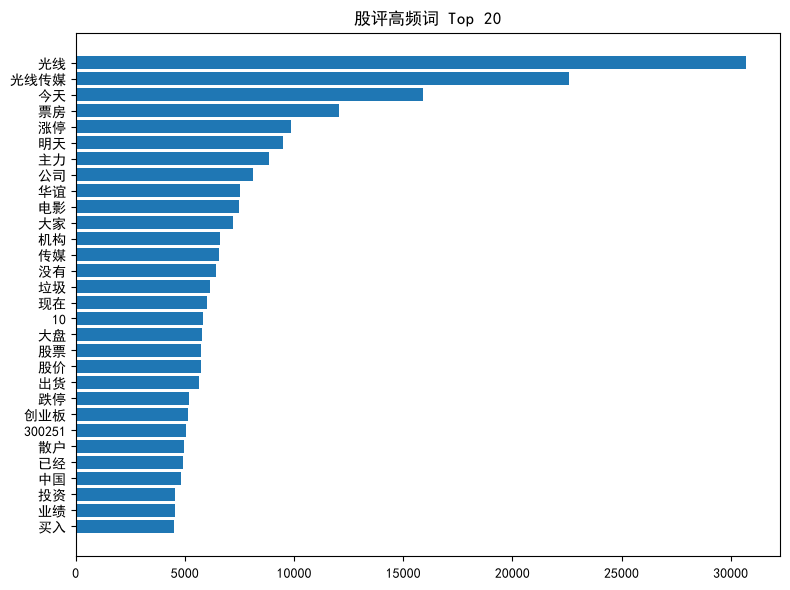

In [10]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei"]   # 中文显示
plt.rcParams["axes.unicode_minus"] = False

top20 = freq.most_common(30)
labels, counts = zip(*top20)

plt.figure(figsize=(8, 6))
plt.barh(range(len(labels))[::-1], counts)
plt.yticks(range(len(labels))[::-1], labels)
plt.title("股评高频词 Top 20")
plt.tight_layout()
plt.savefig("nlp_top20_words.png", dpi=150)
plt.show()

**观察**：Top 20 里哪些词反映了股民情绪？哪些词其实还是噪音（该加进停用词表）？

### 课堂互动·三分钟投票

从你的 Top 20 里挑 3 个词，给每个词贴标签：

- 😊 **情绪词**：本身带看多 / 看空色彩（如「利好」「垃圾」）
- 🔇 **噪音词**：出现很多但没有信息量，该进停用词表
- 🤔 **拿不准**：说不清的

举手示意你的分类，现场汇总。**分歧最大的词往往最有意思**——同一个词在这个语境是情绪、换个语境就是噪音，这正是词频统计需要人工审视的地方。


## Part 3：情感词典打分——词典法完整流程（20 分钟）

自己从零跑通，为下一步画每日情绪曲线做准备。


sum(w in pos_words for w in words) - sum(w in neg_words for w in words)

In [11]:
def load_words(path):
    with open(path, encoding="utf-8") as f:
        return {w.strip() for w in f if w.strip()}

pos_words = load_words("zhang_unformal_pos.txt")
neg_words = load_words("zhang_unformal_neg.txt")
print(f"正面词 {len(pos_words)} 个，负面词 {len(neg_words)} 个")

def sentiment_score(text):
    words = jieba.lcut(text)
    # score
    score = sum(w in pos_words for w in words) - sum(w in neg_words for w in words)
    return  score

# 12 万条全量打分约 2-3 分钟；建议先在抽样上调试通过，再跑全量
df["score"] = df["text"].apply(sentiment_score)
df["label"] = df["score"].apply(lambda s: "正面" if s > 0 else ("负面" if s < 0 else "中性"))

# 查看三类标签的占比：value_counts 统计各标签条数，normalize=True 转成比例，round(3) 保留三位小数
print(df["label"].value_counts(normalize=True).round(3))
print(df.nlargest(3, "score")[["date", "text", "score"]].to_string())
print(df.nsmallest(3, "score")[["date", "text", "score"]].to_string())

正面词 911 个，负面词 964 个
label
中性    0.419
正面    0.310
负面    0.271
Name: proportion, dtype: float64
                      date                                                                                                                                                                                                                                                                                                                                                                                 text  score
48472  2014-10-16 10:57:55                                                                                                  今天你那么多人喊涨停，本大王也来喊一下 涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！涨停！     86
72451  2015-08-19 11:23:16                                                                 

In [12]:
df.head()

,Unnamed: 0,date,modified_date,comment,author,hour,dayofweek,month,text,score,label
0,107189,2011-07-14 21:30:36,2011-07-15,\r\n 88888\...,NaN,21,5,7,88888 88888,0,中性
1,77669,2011-07-14 21:31:46,2011-07-15,\r\n 发行价30块...,NaN,21,5,7,发行价30块 立帖为证,0,中性
2,107188,2011-07-14 21:33:20,2011-07-15,\r\n 3\r\n ...,NaN,21,5,7,3 3,0,中性
3,129105,2011-07-14 22:01:26,2011-07-15,\r\n 好股，拿住！...,更深的蓝888,22,5,7,好股，拿住！ 百元股！请记住我的话！,1,正面
4,107192,2011-07-14 22:20:38,2011-07-15,\r\n 应收账款与日...,NaN,22,5,7,应收账款与日俱增 四川依米康过分依赖大客户 应收账款与日俱增 四川依米康过分依赖大客户,-2,负面


词典法跑通了，但它有天花板（想想反讽）。下一步用 LLM 分析**同样的评论**，两种方法正面比一比。

### 动手④：写一条评论，骗过词典法（约 5 分钟）

词典法只数情感词、不看上下文。**你的任务：写一条实际是看空 / 唱衰、但 `sentiment_score` 算出 ≥ 3 的评论**，成功骗过它。

可用套路：堆正面词 + 阴阳怪气（「太好啦，又能抄底了」）、反问 / 否定（「谁说利好了？」）、先扬后抑（「一直都说要涨，呵呵」）。

写完后**和同桌互换**：先自己判断对方那条是正面还是负面并记下来；Part 4 跑通后，把你们俩的句子也发给 DeepSeek（追加到 `sample10` 重跑一次，或复制那段调用、把 `user_prompt` 换成你们的句子），看 LLM 会不会上当。**把你写的句子、词典法得分、LLM 的判断填进 Part 4 对比表的「能识别反讽吗」一行——这是提交物的一部分。**


In [13]:
# 【动手④】在引号里写你的「伪装成看多的看空评论」，目标：score >= 3
my_text = "呵呵，可以更绿一些"     # ← 写在这里

my_score = sentiment_score(my_text)
print("分词结果：", jieba.lcut(my_text))
print(f"词典法得分：{my_score}  →", "✔ 骗过了！记下这句话，Part 4 拿去考验 LLM" if my_score >= 3 else "✘ 还没骗过，再堆点正面词或换个反讽句式")


分词结果： ['呵呵', '，', '可以', '更', '绿', '一些']
词典法得分：0  → ✘ 还没骗过，再堆点正面词或换个反讽句式


情感词典有没有遗漏的次呢？

## Part 4：接入大模型做情感分析——LLM 法（15 分钟）

词典法是「查表打分」，LLM 法是把文本**发给大模型**、让它像人一样读懂再判断。这里用 `openai` 工具包以 API 形式接入 DeepSeek（OpenAI 兼容接口，改 `base_url` 就能换平台）。

> **成本考虑**：只发 **10 条**评论做示例。10 条短评论约 1–2 千 token，成本不到 1 分钱；但如果把 12 万条全量发给 API，既烧钱又可能触发限流。工程上的习惯是：**先小样本验证逻辑，再决定全量的性价比**。

In [ ]:
import os
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(override=True)   # 读取 week09/.env

client = OpenAI(
    base_url="https://api.deepseek.com",      # OpenAI 兼容接口：换平台只需改这一行
    api_key="os.getenv("DEEPSEEK_API_KEY")",    # os.getenv("DEEPSEEK_API_KEY") 课堂你也可以替换为你的deepseek api key字符串
)

# 抽 10 条（带词典法结果，方便对比）
sample10 = df[["text", "score", "label"]].sample(100, random_state=2011).reset_index(drop=True)

system_prompt = """你是金融文本情感分析助手。对给出的每条股吧评论判断情感倾向：
- 正面：看多、乐观、买入意愿
- 中性：陈述事实、提问、无明显情感
- 负面：看空、抱怨、悲观、反讽

注意反讽和网络用语（如"利好"可能是反讽）。只输出 JSON，不要输出其他内容，格式：
{"results": [{"id": 0, "label": "正面", "reason": "一句话理由"}, ...]}"""

user_prompt = "评论列表：\n" + chr(10).join(
    f"{i}. {t}" for i, t in enumerate(sample10["text"]))

completion = client.chat.completions.create(
    model="deepseek-chat",
    messages=[
        {"role": "system", "content": system_prompt},   # 定角色、定规则、定输出格式
        {"role": "user", "content": user_prompt},       # 带数据
    ],
    temperature=0,          # 分类任务要稳定，不要发散
)

In [26]:
# 先展示发给大模型的原文（编号后的 10 条评论），再展示模型返回的结果
print("【发送的原文】\n" + user_prompt)


【发送的原文】
评论列表：
0. 光线、百度、联想、360联合设立中关村银行将获批 中关村银行是经过中关村管理委员会积极推进的！各个部门相互配合！消息人士透露即将获批！
1. 我也不奢求你这货大涨，趴了一年了。现在你就不能给我爬上20日线吗？天天在均线下玩 我也不奢求你这货大涨，趴了一年了。现在你就不能给我爬上20日线吗？天天在均线下玩，你玩蛋蛋啊！假药王！
2. 利空出尽，周一又是买入良机 嘿嘿，另外还有000917
3. 不明白，四大名捕是三D电影，平均票价才51元？ 光线分成比例是多少？
4. 如日中天那傻货难道已经退出股市不成 如日中天那傻货难道已经退出股市不成
5. 广电总局局长号召影院理性排片《变4》 适当支持国产影片分手大师 美国电影如无节制地进入中国，中国电影产业会有以下严重后果：1，中国电影产业的政策条件将会发生重大转变，国家将不会再给电影产业更利好的条件；2，影片的议价权会被美国片商掌握，包括我们的内部协商都会成为国际谈判；
6. 【独家原创】3月6日（周五)独家盘前重点股研读 【独家原创】3月6日（周五)独家盘前重点股研读[点击查看博客原文]
7. 票房5个亿股价33元、8个亿38元、10个亿42元。 支持
8. 再涨3%就有砸盘的了 再涨3%就有砸盘的了
9. 高开低走完了！ 高开低走完了！
10. （光线传媒资讯）是什么？ 它是光线传媒的？还是随便哪个人都可以装的？它有何居心？谁能说说。
11. 不涨的原因，只有一个。散户多了 不涨的原因，只有一个。散户多了
12. 每天有几百万也很不错 都是纯利啊。很多大片总共票房还就几百万几千万。
13. 我认为庄家开始洗盘了，供大家参考 我认为庄家开始洗盘了，供大家参考
14. 那什么来继续支持你，找不到理由了！ 不想在你这里浪费感情了，一个月的调整还不够吗，伤了心了！
15. 市盈率真高。需要多少利润光线的市盈率才能够从现在的市盈率回到50市盈率 市盈率真高。需要多少利润光线的市盈率才能够从现在的市盈率回到50市盈率
16. 停牌了，知道内情的可以说说了！ 停牌了，知道内情的可以说说了！是好是坏？已经跌了这么多，心里忐忑！
17. 短期内能不能在回50 短期内能不能在回50
18. 可以说王总是一个会感恩的老板[赞][献花] 可以说王总是一个会感恩的老板
19. 怎么洗都不出，拿住20天再说。 买入

In [27]:
print("\n【模型返回】\n" + completion.choices[0].message.content)


【模型返回】
{"results": [{"id": 0, "label": "正面", "reason": "消息面利好，预期获批，语气积极"}, {"id": 1, "label": "负面", "reason": "抱怨股价长期不涨，用词愤怒"}, {"id": 2, "label": "正面", "reason": "认为利空出尽，视为买入良机"}, {"id": 3, "label": "中性", "reason": "提出疑问，无明显情感"}, {"id": 4, "label": "负面", "reason": "用'傻货'称呼，带贬义"}, {"id": 5, "label": "中性", "reason": "陈述行业政策事实与后果分析"}, {"id": 6, "label": "中性", "reason": "博客推广，无明确情感"}, {"id": 7, "label": "正面", "reason": "给出乐观票房与股价预期并支持"}, {"id": 8, "label": "负面", "reason": "预期上涨即遭砸盘，偏悲观"}, {"id": 9, "label": "负面", "reason": "判断高开低走，看空"}, {"id": 10, "label": "中性", "reason": "提问询问，无明显情感"}, {"id": 11, "label": "负面", "reason": "归因散户多导致不涨，抱怨"}, {"id": 12, "label": "正面", "reason": "认为每日几百万纯利很不错"}, {"id": 13, "label": "中性", "reason": "陈述个人判断供参考"}, {"id": 14, "label": "负面", "reason": "表达失望伤心，不想再持有"}, {"id": 15, "label": "负面", "reason": "质疑市盈率过高"}, {"id": 16, "label": "中性", "reason": "询问停牌内情，表达忐忑"}, {"id": 17, "label": "中性", "reason": "提问股价能否回50"}, {"id": 18, "label": "正面", "reason": "称赞王总会感恩，带赞和献

> `messages` 里 system 和 user 的分工是 LLM 应用的通用范式：**system 定角色和规则（每次任务基本不变），user 带具体数据（每次不同）**。这样换任务时只改 user 部分。

解析返回结果，和词典法并排对比：

In [28]:
import json

# 若解析报错：DeepSeek 偶尔会用 ```json 围栏包住输出，把围栏剥掉再 json.loads 即可
results = json.loads(completion.choices[0].message.content)["results"]
sample10["llm_label"] = [r["label"] for r in results]
sample10["llm_reason"] = [r["reason"] for r in results]

In [29]:
sample10

,text,score,label,llm_label,llm_reason
0,光线、百度、联想、360联合设立中关村银行将获批 中关村银行是经过中关村管理委员会积极推进的...,2,正面,正面,消息面利好，预期获批，语气积极
1,我也不奢求你这货大涨，趴了一年了。现在你就不能给我爬上20日线吗？天天在均线下玩 我也不奢求...,2,正面,负面,抱怨股价长期不涨，用词愤怒
2,利空出尽，周一又是买入良机 嘿嘿，另外还有000917,0,中性,正面,认为利空出尽，视为买入良机
3,不明白，四大名捕是三D电影，平均票价才51元？ 光线分成比例是多少？,0,中性,中性,提出疑问，无明显情感
4,如日中天那傻货难道已经退出股市不成 如日中天那傻货难道已经退出股市不成,0,中性,负面,用'傻货'称呼，带贬义
...,...,...,...,...,...
95,政府频频提前兑现利好，用意何在？如今好像股市绑架了政府机构？猜来猜去，其实就是不 政府频频提...,2,正面,中性,分析政策与市场，观点中性偏谨慎
96,散户们，大家赶紧砸盘，一定要弄跌停 散户们，大家赶紧砸盘，一定要弄跌停,-4,负面,负面,号召砸盘弄跌停
97,光线下跌通道已经打开，不知道跌倒多少钱。 这股完了。,-2,负面,负面,认为下跌通道打开、股完了
98,明天我打算在洗一洗 明天我打算在洗一洗,0,中性,中性,陈述明天打算洗一洗


In [30]:
print(sample10[["text", "label", "llm_label", "llm_reason"]].to_string())
agree = (sample10["label"] == sample10["llm_label"]).mean()
print(f"\n两种方法一致率: {agree:.0%}")

                                                                                                                                                                                                                                                               text label llm_label       llm_reason
0                                                                                                                                                                                               光线、百度、联想、360联合设立中关村银行将获批 中关村银行是经过中关村管理委员会积极推进的！各个部门相互配合！消息人士透露即将获批！    正面        正面  消息面利好，预期获批，语气积极
1                                                                                                                                                                      我也不奢求你这货大涨，趴了一年了。现在你就不能给我爬上20日线吗？天天在均线下玩 我也不奢求你这货大涨，趴了一年了。现在你就不能给我爬上20日线吗？天天在均线下玩，你玩蛋蛋啊！假药王！    正面        负面    抱怨股价长期不涨，用词愤怒
2                                                                                                                        

**对比记录**（**提交物**）：

| 对比点 | 词典法（你的代码） | LLM 法（DeepSeek） |
|---|---|---|
| 10 条判断结果 | | |
| 判不一致的评论 | | |
| 能识别反讽吗 | | |
| 成本与速度 | 免费毫秒级，可跑 12 万条 | 约 1 分钱/10 条，全量又贵又慢 |

挑 1–2 条**两种方法判不一致**的评论，说说你站哪边、为什么。

## Part 5：每日情感分数——把文本变成情绪指数（20 分钟）

单条评论的情感有了，现在按天聚合：**当日情感分数 = 当天正面评论数 − 当天负面评论数**。这就是一个从股吧文本「算」出来的情绪指数。

count    2755.000000
mean        1.717241
std        12.037383
min      -123.000000
25%        -2.000000
50%         1.000000
75%         5.000000
max       111.000000
Name: sentiment, dtype: float64


C:\Users\haichao\AppData\Local\Temp\ipykernel_18464\4117714809.py:14: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.tight_layout()
C:\Users\haichao\AppData\Local\Temp\ipykernel_18464\4117714809.py:15: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.savefig("nlp_daily_sentiment.png", dpi=150)
c:\haichao\teaching\2026-fall\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


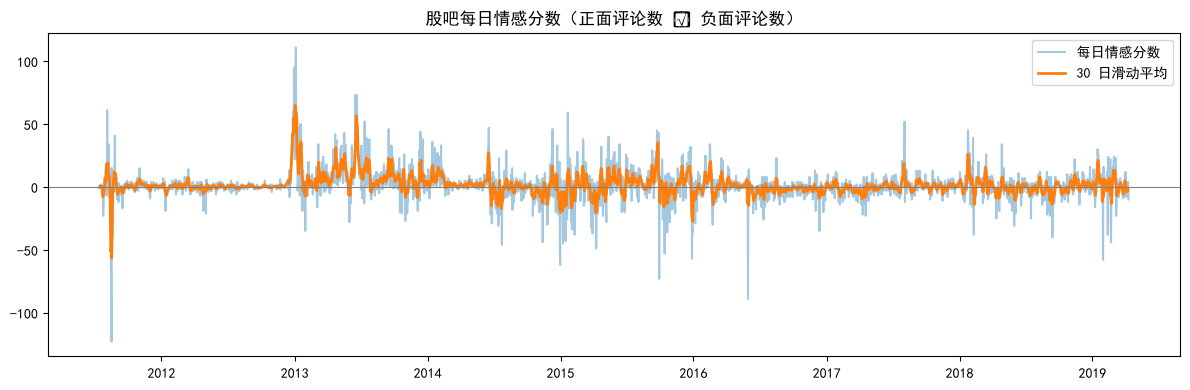

In [32]:
daily = (df.groupby(df["date"].dt.date)["label"]
           .value_counts()
           .unstack(fill_value=0))
daily["sentiment"] = daily.get("正面", 0) - daily.get("负面", 0)
print(daily["sentiment"].describe())

plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily["sentiment"], alpha=0.4, label="每日情感分数")
plt.plot(daily.index, daily["sentiment"].rolling(5, center=True).mean(),
         linewidth=2, label="30 日滑动平均")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("股吧每日情感分数（正面评论数 − 负面评论数）")
plt.legend()
plt.tight_layout()
plt.savefig("nlp_daily_sentiment.png", dpi=150)
plt.show()

**观察**：

1. 情绪曲线有没有明显的极端日？用下面的格子找到那几天，去原始数据里看看当天股民在吵什么
2. **一个隐患**：这个「分数」受当天评论量影响——评论越多的日子，正面−负面的绝对值天然越大。怎么改更公平？（提示：除以当天评论总数，得到净情感比例；放进思考题）

In [ ]:
# 试试：找到情绪最极端的日子
daily["sentiment"].idxmin()
daily["sentiment"].idxmax()

# 再看当天股民在吵什么（把日期换成上面查到的极端日）
df[df["date"].dt.date == pd.Timestamp("2015-06-15").date()][["text", "score"]].head(20)


### 动手⑤：换个口径，重算情绪指数（约 5 分钟）

上面「观察」第 2 点说绝对数受评论量影响。现在动手验证：把「正面 − 负面」换成**净情感比例**——（正面 − 负面）÷ 当天评论总数——重画曲线，和上图对比，重点看**评论量暴涨的日子**（极端日附近）形状变了吗？

做完带着新口径进入 Part 6：`daily` 里新增的 `sentiment_ratio` 列会跟着 merge 进 `merged`。跑完 Part 6 后回到本格底部取消注释、对比两种口径的 r——**口径变了，结论会不会变？**（这就是思考题 2）


In [33]:
daily.head()

label,中性,正面,负面,sentiment
date,,,,
2011-07-14,3,1,2,-1
2011-07-15,1,1,0,1
2011-07-16,0,1,0,1
2011-07-17,0,0,1,-1
2011-07-18,3,2,0,2


C:\Users\haichao\AppData\Local\Temp\ipykernel_18464\870282562.py:12: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.tight_layout()
c:\haichao\teaching\2026-fall\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


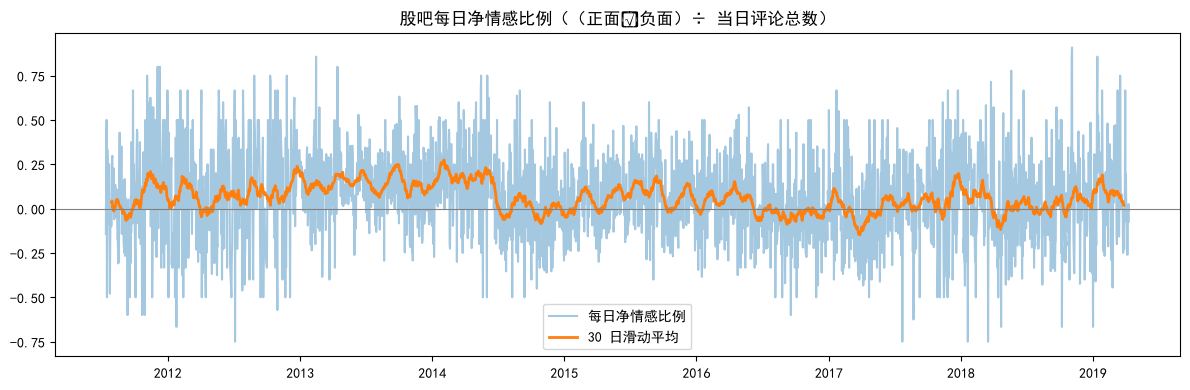

In [35]:
# ① 填空：净情感比例 =（正面 − 负面）÷ 当天评论总数（提示：三列之和是总数）
daily["sentiment_ratio"] = (daily["正面"] - daily["负面"]) / (daily["正面"] + daily["负面"] + daily["中性"] + 1)

# ② 重画曲线，和上面的绝对数口径对比
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily["sentiment_ratio"], alpha=0.4, label="每日净情感比例")
plt.plot(daily.index, daily["sentiment_ratio"].rolling(30, center=True).mean(),
         linewidth=2, label="30 日滑动平均")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("股吧每日净情感比例（（正面−负面）÷ 当日评论总数）")
plt.legend()
plt.tight_layout()
plt.show()

# ③ 跑完 Part 6 后回到这里，取消注释，对比两种口径的相关系数
# r_same_ratio = merged["sentiment_ratio"].corr(merged["pct_chg"])
# r_next_ratio = merged["sentiment_ratio"].corr(merged["next_pct_chg"])
# print(f"比例口径：当日 r = {r_same_ratio:.3f}，次日 r = {r_next_ratio:.3f}")
# print(f"绝对数口径：当日 r = {r_same:.3f}，次日 r = {r_next:.3f}")


## Part 6：情绪与股价——相关系数（20 分钟）

情绪曲线有了，股价数据也备好了（`300251_daily.csv`）。现在回答一个金融文本分析的经典问题：**股吧情绪和股价涨跌幅有关系吗？**

merge 函数鼓励我们重视

In [36]:
price = pd.read_csv("300251_daily.csv", parse_dates=["trade_date"])
price["day"] = price["trade_date"].dt.date
print(price.head())

# 情绪表（Part 5 的 daily）与行情表按日期对齐
# 用 inner join：周末和节假日发评论没有对应行情，自动剔除
merged = daily.reset_index().merge(
    price[["day", "close", "pct_chg"]],
    left_on="date", right_on="day", how="inner")
print(f"匹配到 {len(merged)} 个交易日")

# 同日相关：情绪是「同步反映」涨跌吗？
r_same = merged["sentiment"].corr(merged["pct_chg"])

# 滞后相关：情绪能「预测」明天吗？（把涨跌幅向前挪一天）
merged["next_pct_chg"] = merged["pct_chg"].shift(-1)
r_next = merged["sentiment"].corr(merged["next_pct_chg"])

print(f"当日情绪 vs 当日涨跌幅: r = {r_same:.3f}")
print(f"当日情绪 vs 次日涨跌幅: r = {r_next:.3f}")

  trade_date  close  pct_chg         day
0 2011-08-03  74.00    40.95  2011-08-03
1 2011-08-04  72.67    -1.80  2011-08-04
2 2011-08-05  75.44     3.81  2011-08-05
3 2011-08-08  74.09    -1.79  2011-08-08
4 2011-08-09  79.60     7.44  2011-08-09
匹配到 1732 个交易日
当日情绪 vs 当日涨跌幅: r = 0.489
当日情绪 vs 次日涨跌幅: r = 0.008


画散点图看关系的形状（**提交物之一**）：

C:\Users\haichao\AppData\Local\Temp\ipykernel_18464\2792528798.py:15: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.tight_layout()
C:\Users\haichao\AppData\Local\Temp\ipykernel_18464\2792528798.py:16: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.savefig("nlp_sentiment_vs_return.png", dpi=150)
c:\haichao\teaching\2026-fall\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


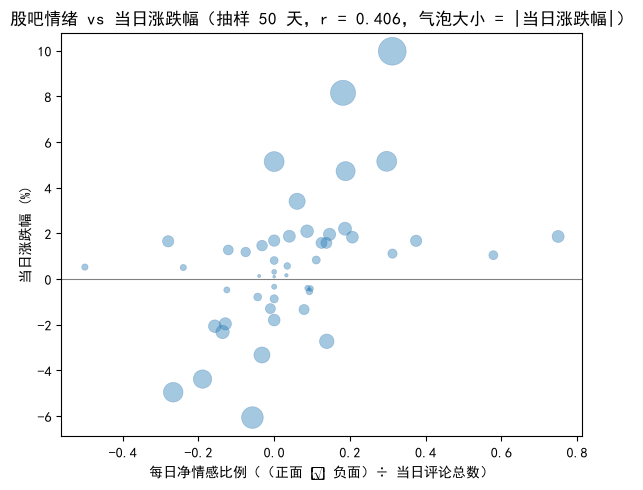

In [37]:
# 气泡图：气泡大小 = 当日涨跌幅的绝对值（面积不能为负，方向已由 y 轴表达）
# 全量上千个交易日太密，随机抽 50 天展示（改 random_state 换一批）
plot_data = merged.sample(50, random_state=42)
size = plot_data["pct_chg"].abs()
r_plot = merged["sentiment_ratio"].corr(merged["pct_chg"])  # r 是总体统计量，仍用全量算

plt.figure(figsize=(6, 5))
plt.scatter(plot_data["sentiment_ratio"], plot_data["pct_chg"],
            s=size / size.max() * 400,  # 面积归一化，最大气泡 400
            alpha=0.4, edgecolors="steelblue", linewidths=0.5)
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("每日净情感比例（（正面 − 负面）÷ 当日评论总数）")
plt.ylabel("当日涨跌幅 (%)")
plt.title(f"股吧情绪 vs 当日涨跌幅（抽样 50 天，r = {r_plot:.3f}，气泡大小 = |当日涨跌幅|）")
plt.tight_layout()
plt.savefig("nlp_sentiment_vs_return.png", dpi=150)
plt.show()

**解读标尺**：|r| < 0.1 几乎不相关；0.1–0.3 弱；0.3–0.5 中等；> 0.5 强。样本大时（这里上千个交易日）很小的 r 也可能统计显著，但**显著 ≠ 有用**。

**观察**：

1. 两个 r 哪个更大？如果当日相关明显强于次日相关，说明情绪更像涨跌的「果」而不是「因」——当天涨了股民才兴奋
2. 极端值的影响：2011-08-03 上市首日 `pct_chg` 高达 +40.95%，2015 年牛市顶部也有极端波动。用 Spearman（按秩算相关，抗极端值）重算一次，r 变了多少？
3. **相关 ≠ 因果**：就算 r 不小，也说明不了「看多情绪推动股价」——可能是股价推动情绪，也可能两者都被第三因素（大盘、消息面）驱动

In [38]:
# 试试：用 Spearman 相关系数（抗极端值）重算
# next_pct_chg 来自上一格的 shift(-1)，即下一交易日涨跌幅（最后一行为空，corr 自动剔除）
r_spearman_same = merged["sentiment"].corr(merged["pct_chg"], method="spearman")
r_spearman_next = merged["sentiment"].corr(merged["next_pct_chg"], method="spearman")
print(f"Spearman r（当日）= {r_spearman_same:.3f}")
print(f"Spearman r（次日）= {r_spearman_next:.3f}")


Spearman r（当日）= 0.488
Spearman r（次日）= 0.017


### 相关系数公式

**① Pearson 相关系数**（`corr()` 的默认值，`method="pearson"`）

$$r = \frac{\sum_{t=1}^{n}(x_t - \bar{x})(y_t - \bar{y})}{\sqrt{\sum_{t=1}^{n}(x_t - \bar{x})^2}\;\sqrt{\sum_{t=1}^{n}(y_t - \bar{y})^2}}$$

衡量**线性**相关：分子刻画两变量「同向变动」的程度，分母把量纲约掉。这里 $x$ 是每日情绪分数，$y$ 是当日（或次日）涨跌幅。平方项会放大极端值的权重——上市首日 +40.95% 那样的点会显著拉动 $r$。

**② Spearman 相关系数**（`method="spearman"`）

先把两个变量各自替换成**秩（名次）** $R(x_t)$、$R(y_t)$，再对秩套用 Pearson 公式；无并列名次时等价于：

$$r_s = 1 - \frac{6\sum_{t=1}^{n} d_t^2}{n(n^2 - 1)}, \qquad d_t = R(x_t) - R(y_t)$$

只保留「大小顺序」信息：最大值比第二大值多 1% 还是多 40%，名次都只差 1，因此**抗极端值**；衡量的是**单调**关系（不要求线性）。

两者取值都在 $[-1, 1]$：$>0$ 正相关，$<0$ 负相关，接近 0 表示没有（线性/单调）相关。


## 提交

- 这个 notebook 本身（Part 0–6 完整流程，从上到下能跑通）
- 三张图：高频词 Top 20、每日情感分数曲线、情绪 vs 涨跌幅散点图
- Part 6 的两个相关系数（同日 + 次日）和一句话解读
- Part 4 的对比表（填好）+ 3–5 句结论：词典法和 LLM 法各输在哪、你会在自己项目里用哪种（考虑成本）
- 当日在 `journal.md` 追加 1 条（今天做了什么 / 关键决定 / 学习并掌握的新东西 / 卡点 / 互助记录）

## 自检（达标线）

- [ ] 能说清为什么中文必须分词、以及自定义词典解决了什么问题
- [ ] 能指出至少 1 条分词错误、并说出你会往 `userdict.txt` 里加什么词
- [ ] Part 4 的 LLM 调用跑通了，对比表里两种方法各有具体数字
- [ ] 每日情感曲线画出来了，并指出一个指数的局限（评论量偏差或反讽误判）
- [ ] 两个相关系数算出来了，并能说出「当日相关 vs 次日相关」谁大说明什么
- [ ] 能说出为什么示例只发 10 条（成本与限流），以及全量 12 万条该怎么做
- [ ] 结论不是「AI 更聪明」这种空话，而是指出具体差异（如：LLM 法识别了反讽，词典法把它计为正面）

## 思考题（连接 LLM）

1. **分词的歧义**：「南京市长江大桥」可以切成「南京市 / 长江大桥」也可以是「南京市长 / 江大桥」。jieba 靠什么决定切法？什么情况下会切错？
2. **情绪指数的口径**：Part 5 的「正面数 − 负面数」和「（正面 − 负面）÷ 当日评论总数」哪个更适合当情绪指数？各会在什么情况下误导你？
3. **LLM 不用 jieba**：LLM 的 tokenizer（如 BPE）把文本切成 subword 而不是「词」。为什么 LLM 不需要人工维护 `userdict.txt` 这样的词典？
4. **词典法的天花板**：找到一条你的词典法判错、但 LLM 判对的评论（比如反讽）。LLM 靠什么做到了词典法做不到的事？（提示：回看 `llm.ipynb` 里 Attention 部分——每个词「看」它的上下文）
5. **成本与工程**：如果老师要求给全部 12 万条评论都打上 LLM 情感标签，你会怎么设计方案控制成本？（提示：抽样估计、批量请求、便宜的小模型、或只对「词典法不确定」的评论调用 LLM）
6. **情绪能预测股价吗**：如果 Part 6 里次日相关的 r 非常小，能得出「股吧情绪没有预测价值」的结论吗？（提示：情绪指数的口径、极端行情日、以及「预测」需要的是显著为正的 r_next 而不只是接近 0 的相关性）


## 学习资料

- `text_data_processing_2.ipynb`（向量与余弦相似度：课后想深入「文本变成向量」的同学看这个，涉及 TF-IDF 的进阶用法）
- 视频（超星学习通）：3.1/3.2 词语切分；4.1 文本量化 TF-IDF（课后延伸，本次课上不做）
- `llm-key-guide.md`（API Key 申请路径与安全红线）
- DeepSeek API 文档（OpenAI 兼容接口）：https://api-docs.deepseek.com
- tushare 行情接口（`300251_daily.csv` 的来源，进阶可自己拉取）：https://tushare.pro/document/2?doc_id=27
- jieba 文档：https://github.com/fxsjy/jieba